# ARTI 402 — Deep Learning
## Lab 11 — Generative Models: VAEs and GANs

**Week 11 · Variational Autoencoders and Generative Adversarial Networks**
Making the latent space mean something, and then inventing data that never existed.

---
## Setup

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

np.set_printoptions(precision=3, suppress=True)

digits = load_digits()
X = digits.data / 16.0
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y)

print("train:", X_train.shape, " test:", X_test.shape)
print("the same 8 x 8 digits as Lab 9")

train: (1347, 64)  test: (450, 64)
the same 8 x 8 digits as Lab 9


In [2]:
from arti402_figures import (draw_vae_architecture, draw_reparameterization,
                             draw_gan_setup, draw_gan_progress,
                             draw_digit_grid, draw_latent_space)

print("figure helpers loaded")

figure helpers loaded


---
# Stage 1 · The gap left at the end of Lab 9

## Idea 1 — Invent a code and see what comes out

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))


class VAE:
    """64 -> 32 -> (mu, logvar) of size L -> 32 -> 64.

    With beta = 0 in the loss this behaves as Lab 9's plain autoencoder.
    With beta = 1 it is a variational autoencoder.
    """

    def __init__(self, L=8, H=32, seed=0):
        r = np.random.RandomState(seed)
        he = lambda a, b: r.randn(a, b) * np.sqrt(2.0 / a)
        self.W1,  self.b1  = he(64, H), np.zeros(H)
        self.Wmu, self.bmu = he(H, L),  np.zeros(L)
        self.Wlv, self.blv = he(H, L),  np.zeros(L)
        self.W3,  self.b3  = he(L, H),  np.zeros(H)
        self.W4,  self.b4  = he(H, 64), np.zeros(64)
        self.L = L

    def encode(self, X):
        h = np.maximum(0, X @ self.W1 + self.b1)
        return h, h @ self.Wmu + self.bmu, h @ self.Wlv + self.blv

    def decode(self, z):
        h2 = np.maximum(0, z @ self.W3 + self.b3)
        return h2, sigmoid(h2 @ self.W4 + self.b4)


print("VAE class ready - note the encoder returns TWO things, not one")

VAE class ready - note the encoder returns TWO things, not one


---
# Stage 2 · Two new ideas

## Idea 2 — Make the code a distribution

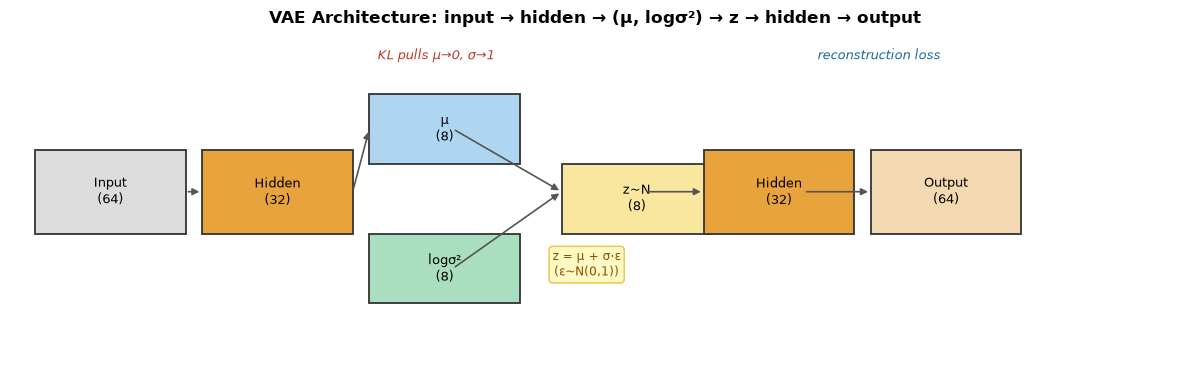

In [4]:
draw_vae_architecture(d_in=64, hidden=32, latent=8)
plt.show()

## Idea 3 — The reparameterization trick

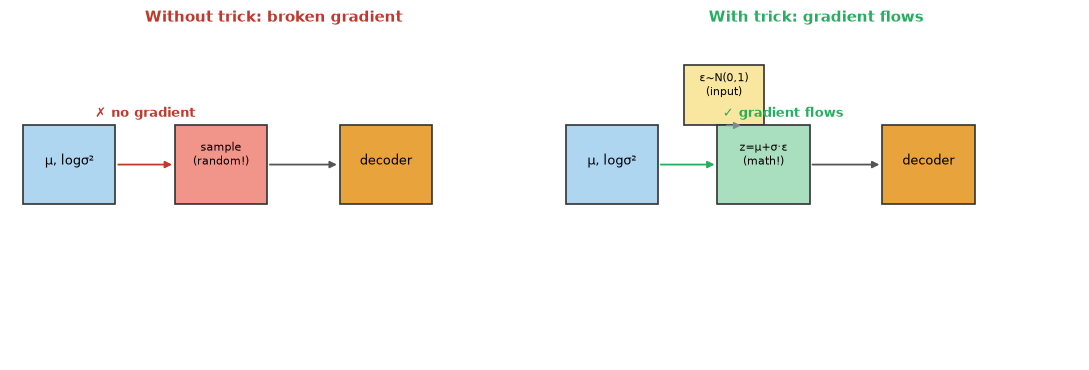

In [5]:
draw_reparameterization()
plt.show()

### Exercise 1 — the trick, in one line

In [6]:
def reparameterize(mu, logvar, rng):
    """Draw z = mu + sigma * eps, with eps from a standard normal.

    Returns (eps, z) - eps is kept because the backward pass needs it.
    """
    # TODO 1: draw eps, the same shape as mu, from a standard normal
    eps = rng.randn(*mu.shape)

    # TODO 2: sigma from logvar - exp of half the log variance
    sigma = np.exp(0.5 * logvar)

    # TODO 3: z = mu + sigma * eps
    z = mu + sigma * eps

    return eps, z


# --- self-check -------------------------------------------------
rng = np.random.RandomState(0)
mu_t = np.array([[0.0, 5.0]])
lv_t = np.array([[np.log(1.0), np.log(0.0001)]])   # second dim almost certain
samples = np.array([reparameterize(mu_t, lv_t, rng)[1][0] for _ in range(2000)])

print(f"dim 0 (variance 1.0000): mean {samples[:,0].mean():6.3f}  std {samples[:,0].std():.3f}")
print(f"dim 1 (variance 0.0001): mean {samples[:,1].mean():6.3f}  std {samples[:,1].std():.3f}")

assert abs(samples[:, 0].std() - 1.0) < 0.1, "dim 0 should have std about 1"
assert samples[:, 1].std() < 0.05, "dim 1 said it was certain - it should barely move"
assert abs(samples[:, 1].mean() - 5.0) < 0.05, "dim 1 should sit at its mu"
print("\nA confident dimension barely moves. An uncertain one wanders.")

dim 0 (variance 1.0000): mean -0.044  std 0.983
dim 1 (variance 0.0001): mean  5.000  std 0.010

A confident dimension barely moves. An uncertain one wanders.


### Exercise 2 — the KL term

$$D_{KL} = -\tfrac{1}{2}\sum_j \left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

In [7]:
def kl_divergence(mu, logvar):
    """Mean KL divergence per sample, against a standard normal."""
    n = len(mu)
    # TODO: the formula above, summed over everything, divided by n
    #       (np.exp(logvar) is sigma squared)
    return -0.5 * np.sum(1 + logvar - mu**2 - np.exp(logvar)) / n


# --- self-check -------------------------------------------------
perfect = kl_divergence(np.zeros((4, 3)), np.zeros((4, 3)))
shifted = kl_divergence(np.full((4, 3), 2.0), np.zeros((4, 3)))
narrow  = kl_divergence(np.zeros((4, 3)), np.full((4, 3), np.log(0.01)))

print(f"mu=0, var=1   (already standard normal) : {perfect:.3f}")
print(f"mu=2, var=1   (drifted off centre)      : {shifted:.3f}")
print(f"mu=0, var=0.01 (too confident)          : {narrow:.3f}")

assert abs(perfect) < 1e-9, "a standard normal should score exactly 0"
assert shifted > 5, "drifting off centre must be punished"
assert narrow > 5, "collapsing the variance must be punished too"

mu=0, var=1   (already standard normal) : -0.000
mu=2, var=1   (drifted off centre)      : 6.000
mu=0, var=0.01 (too confident)          : 5.423


### Exercise 3 — the full loss

$$\mathcal{L} = \underbrace{\text{BCE}(\hat{x}, x)}_{\text{rebuild it}} \; + \; \beta \cdot \underbrace{D_{KL}}_{\text{keep it tidy}}$$

In [8]:
def vae_loss(X, x_hat, mu, logvar, beta=1.0):
    """Returns (reconstruction, kl, total). Reconstruction is binary cross-entropy."""
    n = len(X)
    eps = 1e-9
    recon = -np.sum(X * np.log(x_hat + eps) + (1 - X) * np.log(1 - x_hat + eps)) / n

    # TODO 1: the KL term, using the function you wrote
    kl = kl_divergence(mu, logvar)

    # TODO 2: the total - reconstruction plus beta times KL
    total = recon + beta * kl

    return recon, kl, total


# --- self-check ---
m_ = VAE(L=8, seed=0)
h_, mu_, lv_ = m_.encode(X_train[:16])
_, z_ = reparameterize(mu_, lv_, np.random.RandomState(0))
_, xh_ = m_.decode(z_)
r_, k_, t_ = vae_loss(X_train[:16], xh_, mu_, lv_, beta=1.0)
print(f"untrained:  reconstruction {r_:.2f}   KL {k_:.3f}   total {t_:.2f}")
assert abs(t_ - (r_ + k_)) < 1e-9, "with beta=1 the total is just the sum"
r0, k0, t0 = vae_loss(X_train[:16], xh_, mu_, lv_, beta=0.0)
assert abs(t0 - r0) < 1e-6, "with beta=0 the KL should not contribute"
print("with beta = 0 the loss is reconstruction only - a plain autoencoder")

untrained:  reconstruction 56.95   KL 1.941   total 58.89
with beta = 0 the loss is reconstruction only - a plain autoencoder


### Checkpoint 1

**1.** The encoder outputs `mu` and `logvar` instead of one code vector. What does the pair say that a single vector cannot?

> A single vector says "this image is *at* this exact point in latent space." The pair `(mu, logvar)` says "this image lives *somewhere around* `mu`, and `logvar` tells you how uncertain I am — a small variance means the image maps to a tight region, a large one means the boundary is blurry." This uncertainty is precisely what lets the KL term regularise the space.

**2.** Explain in two sentences why sampling inside the network breaks backpropagation, and how moving `eps` to the input fixes it.

> Backpropagation requires every operation to have a derivative with respect to its inputs, but "draw a random sample" is a non-differentiable operation — there is no gradient of "randomness" with respect to `mu`. By writing `z = mu + sigma × eps` with `eps` drawn *outside* and treated as a fixed input, `z` becomes a simple arithmetic expression in `mu` and `sigma`, so gradients flow back through the addition and multiplication without obstruction.

**3.** The KL term punishes both drifting away from the origin *and* becoming too certain. Why would punishing only the first not be enough?

> Without punishing overconfidence the encoder can place every class at the origin (`mu = 0`) but collapse the variance to essentially zero — encoding each image as a delta-function spike. The decoder then memorises these delta functions perfectly, the KL "mean-drift" penalty is satisfied, but randomly sampled points from `N(0,1)` fall in the gaps between the spikes and produce noise. Punishing small `sigma` forces the codes to genuinely overlap with the prior distribution.

---
# Stage 3 · Training it

## Idea 4 — The backward pass, provided and checked

In [9]:
PARAMS = ['W1', 'b1', 'Wmu', 'bmu', 'Wlv', 'blv', 'W3', 'b3', 'W4', 'b4']


def backward(m, X, h, mu, lv, eps, z, h2, x_hat, beta):
    n = len(X)
    g = {}
    da4 = (x_hat - X) / n                       # sigmoid + BCE, fused as in Lab 2
    g['W4'] = h2.T @ da4;  g['b4'] = da4.sum(0)
    dh2 = da4 @ m.W4.T;    dh2[h2 <= 0] = 0
    g['W3'] = z.T @ dh2;   g['b3'] = dh2.sum(0)
    dz = dh2 @ m.W3.T

    dmu = dz + beta * mu / n                                        # recon + KL
    dlv = dz * eps * 0.5 * np.exp(0.5 * lv) + beta * 0.5 * (np.exp(lv) - 1) / n

    g['Wmu'] = h.T @ dmu;  g['bmu'] = dmu.sum(0)
    g['Wlv'] = h.T @ dlv;  g['blv'] = dlv.sum(0)
    dh = dmu @ m.Wmu.T + dlv @ m.Wlv.T;  dh[h <= 0] = 0
    g['W1'] = X.T @ dh;    g['b1'] = dh.sum(0)
    return g


def train_vae(L=8, H=32, beta=1.0, epochs=400, batch_size=64, lr=2e-3,
              seed=0, data=None):
    Xd = X_train if data is None else data
    m = VAE(L, H, seed=seed)
    rng = np.random.RandomState(seed)
    adam = {k: [np.zeros_like(getattr(m, k)), np.zeros_like(getattr(m, k))]
            for k in PARAMS}
    t = 0
    for ep in range(epochs):
        perm = rng.permutation(len(Xd))
        for s in range(0, len(Xd), batch_size):
            Xb = Xd[perm[s:s + batch_size]]
            h, mu, lv = m.encode(Xb)
            eps, z = reparameterize(mu, lv, rng)
            h2, xh = m.decode(z)
            g = backward(m, Xb, h, mu, lv, eps, z, h2, xh, beta)
            t += 1
            for k, G in g.items():
                mt, vt = adam[k]
                mt[:] = 0.9 * mt + 0.1 * G
                vt[:] = 0.999 * vt + 0.001 * G * G
                P = getattr(m, k)
                P -= lr * (mt / (1 - 0.9 ** t)) / (np.sqrt(vt / (1 - 0.999 ** t)) + 1e-8)
    return m


def evaluate(m, Xd, beta=1.0, seed=7):
    h, mu, lv = m.encode(Xd)
    eps, z = reparameterize(mu, lv, np.random.RandomState(seed))
    h2, xh = m.decode(z)
    r, k, tot = vae_loss(Xd, xh, mu, lv, beta)
    return r, k, mu


print("training machinery ready")

training machinery ready


### Exercise 4 — check the gradients, as always

In [10]:
m_chk = VAE(L=3, H=16, seed=1)
Xb = X_train[:6]
h, mu, lv = m_chk.encode(Xb)
eps_fixed, z = reparameterize(mu, lv, np.random.RandomState(0))
h2, xh = m_chk.decode(z)
g = backward(m_chk, Xb, h, mu, lv, eps_fixed, z, h2, xh, beta=1.0)


def loss_with_fixed_eps(m, X, eps):
    h, mu, lv = m.encode(X)
    z = mu + np.exp(0.5 * lv) * eps              # same eps every time
    h2, xh = m.decode(z)
    r, k, total = vae_loss(X, xh, mu, lv, beta=1.0)
    return total


worst = 0.0
step = 1e-5
for name in PARAMS:
    P = getattr(m_chk, name)
    for trial in range(6):
        ix = tuple(np.random.RandomState(trial).randint(0, s) for s in P.shape)
        original = P[ix]
        # TODO: central difference - nudge up, nudge down, put it back
        P[ix] = original + step;  L_plus  = loss_with_fixed_eps(m_chk, Xb, eps_fixed)
        P[ix] = original - step;  L_minus = loss_with_fixed_eps(m_chk, Xb, eps_fixed)
        P[ix] = original
        numeric = (L_plus - L_minus) / (2 * step)
        worst = max(worst, abs(numeric - g[name][ix]) / max(abs(numeric), 1e-8))

print(f"worst relative error across all 10 parameter arrays: {worst:.2e}")
assert worst < 1e-4, "the backward pass and the definition of a derivative disagree"
print("the gradients are correct")

worst relative error across all 10 parameter arrays: 1.98e-06
the gradients are correct


### Exercise 5 — train it, and then invent a digit

In [11]:
t0 = time.time()
ae  = train_vae(L=8, beta=0.0, epochs=400)      # plain autoencoder
vae = train_vae(L=8, beta=1.0, epochs=400)      # variational autoencoder
print(f"both trained in {time.time() - t0:.1f}s")

for name, m, b in [("plain AE (beta=0)", ae, 0.0), ("VAE (beta=1)", vae, 1.0)]:
    r, k, mu = evaluate(m, X_test, beta=b)
    print(f"{name:20}  reconstruction {r:6.2f}   KL {k:6.2f}   "
          f"code std {mu.std():.2f}")

print("\nThe KL term asked for code std = 1. Look at which model delivered it.")

both trained in 3.2s
plain AE (beta=0)     reconstruction  17.24   KL  86.33   code std 2.46
VAE (beta=1)          reconstruction  20.90   KL   3.49   code std 0.67

The KL term asked for code std = 1. Look at which model delivered it.


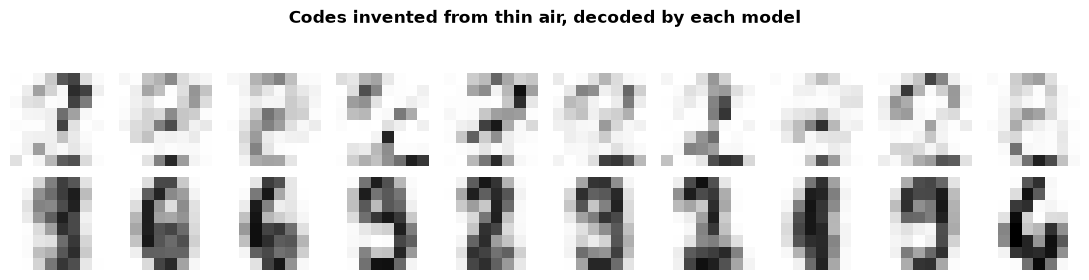

In [12]:
rng_gen = np.random.RandomState(42)

# TODO 1: draw 10 codes from a STANDARD NORMAL, shape (10, 8)
z_invented = rng_gen.randn(10, 8)

# TODO 2: decode them with each model (decode returns two things; keep the second)
_, made_by_ae  = ae.decode(z_invented)
_, made_by_vae = vae.decode(z_invented)

draw_digit_grid([("plain AE", made_by_ae), ("VAE", made_by_vae)],
                suptitle="Codes invented from thin air, decoded by each model")
plt.show()

assert z_invented.shape == (10, 8), "ten codes, eight numbers each"

### Exercise 6 — measure it, do not just look

In [13]:
judge = LogisticRegression(max_iter=3000).fit(X_train, y_train)
print(f"judge's accuracy on real digits: {judge.score(X_test, y_test):.3f}")
print(f"judge's confidence on real digits: "
      f"{judge.predict_proba(X_test).max(axis=1).mean():.3f}\n")


def generation_score(m, latent=8, n=300, seed=42):
    """Mean confidence of the judge on n images invented by this model."""
    zs = np.random.RandomState(seed).randn(n, latent)
    # TODO: decode zs, then return the judge's mean max probability
    _, generated = m.decode(zs)
    return judge.predict_proba(generated).max(axis=1).mean()


print(f"plain AE (beta=0) : {generation_score(ae):.3f}")
print(f"VAE      (beta=1) : {generation_score(vae):.3f}")

assert generation_score(vae) > generation_score(ae), \
    "the VAE should generate more convincingly"

judge's accuracy on real digits: 0.969
judge's confidence on real digits: 0.903

plain AE (beta=0) : 0.495
VAE      (beta=1) : 0.676


---
# Stage 4 · Turning the dial too far

## Idea 5 — Posterior collapse

In [14]:
print(f"{'beta':>6}{'recon':>9}{'KL':>8}{'code std':>11}{'judge confidence':>19}")
results = {}
for beta in [0.0, 1.0, 4.0]:
    m = train_vae(L=8, beta=beta, epochs=400)
    r, k, mu = evaluate(m, X_test, beta=beta)
    conf = generation_score(m)
    results[beta] = (r, k, mu.std(), conf)
    print(f"{beta:6.1f}{r:9.2f}{k:8.2f}{mu.std():11.2f}{conf:19.3f}")

print(f"\nreal digits, for reference:"
      f"{judge.predict_proba(X_test).max(axis=1).mean():>36.3f}")

  beta    recon      KL   code std   judge confidence
   0.0    17.24   86.33       2.46              0.495
   1.0    20.90    3.49       0.67              0.676
   4.0    27.21    0.00       0.01              0.300

real digits, for reference:                               0.903


### Exercise 7 — walking through the latent space

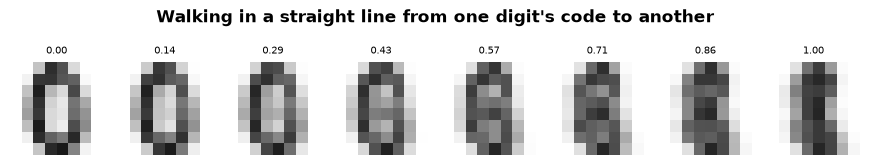

the judge reads this sequence as: [np.int64(0), np.int64(0), np.int64(0), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(1)]


In [15]:
i = int(np.where(y_test == 0)[0][0])     # a zero
j = int(np.where(y_test == 8)[0][0])     # an eight

_, mu_pair, _ = vae.encode(X_test[[i, j]])

alphas = np.linspace(0, 1, 8)
# TODO: for each alpha, blend the two codes: (1-a)*first + a*second
path = np.array([(1 - a) * mu_pair[0] + a * mu_pair[1] for a in alphas])

_, frames = vae.decode(path)

draw_digit_grid([("0 -> 8", frames)], n=len(alphas),
                titles=[f"{a:.2f}" for a in alphas],
                suptitle="Walking in a straight line from one digit's code to another")
plt.show()

print("the judge reads this sequence as:", list(judge.predict(frames)))
assert path.shape == (8, 8), "eight steps, eight numbers each"

---
# Stage 5 · GANs: a completely different bargain

## Idea 6 — Stop measuring, start competing

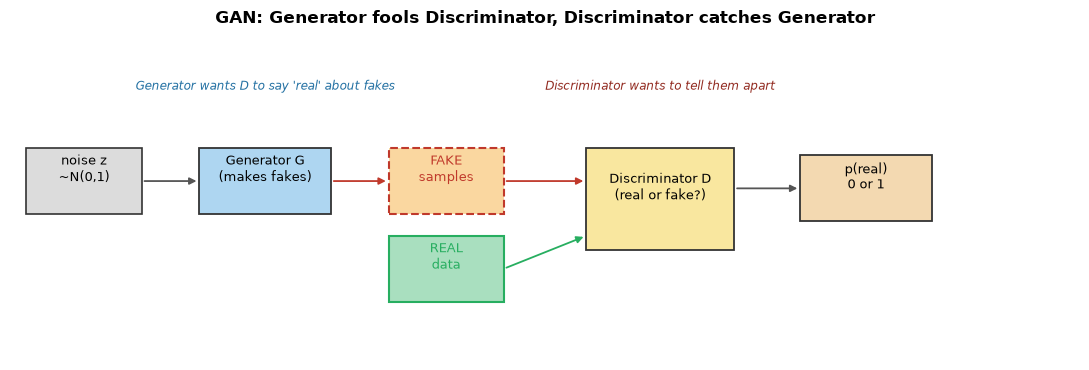

In [16]:
draw_gan_setup()
plt.show()

### Exercise 8 — a GAN in one dimension

In [17]:
class MLP:
    """A small network with its own forward/backward, as in Lab 5."""

    def __init__(s, sizes, seed=0, out_sigmoid=False):
        r = np.random.RandomState(seed)
        s.W, s.b, s.out_sigmoid = [], [], out_sigmoid
        for a, b in zip(sizes[:-1], sizes[1:]):
            s.W.append(r.randn(a, b) * np.sqrt(2.0 / a))
            s.b.append(np.zeros(b))

    def forward(s, x):
        s.acts = [x]; h = x
        for i, (W, b) in enumerate(zip(s.W, s.b)):
            z = h @ W + b
            last = (i == len(s.W) - 1)
            h = sigmoid(z) if (last and s.out_sigmoid) else (z if last else np.maximum(0, z))
            s.acts.append(h)
        return h

    def backward(s, dout):
        gW = [None] * len(s.W); gb = [None] * len(s.b); d = dout
        for i in range(len(s.W) - 1, -1, -1):
            gW[i] = s.acts[i].T @ d; gb[i] = d.sum(0)
            d = d @ s.W[i].T
            if i > 0: d = d * (s.acts[i] > 0)
        return gW, gb, d                      # the last return is d(loss)/d(input)

    def step(s, gW, gb, lr):
        for i in range(len(s.W)):
            s.W[i] -= lr * gW[i]; s.b[i] -= lr * gb[i]


print("MLP ready")

MLP ready


In [18]:
rng = np.random.RandomState(0)
G = MLP([1, 32, 32, 1], seed=1)                    # noise -> a number
D = MLP([1, 32, 32, 1], seed=2, out_sigmoid=True)  # a number -> p(real)

n, lr, D_STEPS = 256, 0.02, 4
steps, g_mean, g_std, p_real, p_fake = [], [], [], [], []

for step in range(3001):
    # ---- train the discriminator: say 1 for real, 0 for fake
    for _ in range(D_STEPS):
        real = rng.normal(3, 0.5, (n, 1))
        fake = G.forward(rng.randn(n, 1))

        d_real = D.forward(real)
        # TODO 1: the discriminator wants d_real to be 1.
        #         With a sigmoid output and cross-entropy, the gradient
        #         at the output is (prediction - target) / n.
        gW1, gb1, _ = D.backward((d_real - 1) / n)

        d_fake = D.forward(fake)
        # TODO 2: the same, but the target for a fake is 0
        gW2, gb2, _ = D.backward((d_fake - 0) / n)

        D.step([a + b for a, b in zip(gW1, gW2)],
               [a + b for a, b in zip(gb1, gb2)], lr)

    # ---- train the generator: make the discriminator say "real" about fakes
    fake = G.forward(rng.randn(n, 1))
    d_fake = D.forward(fake)
    # TODO 3: the generator wants d_fake to be 1. Same expression as TODO 1.
    #         We keep the THIRD return value: the gradient w.r.t. D's input,
    #         which is G's output.
    _, _, d_input = D.backward((d_fake - 1) / n)

    gW, gb, _ = G.backward(d_input)
    G.step(gW, gb, lr)

    if step % 600 == 0:
        s_ = G.forward(rng.randn(2000, 1))
        steps.append(step); g_mean.append(float(s_.mean())); g_std.append(float(s_.std()))
        p_real.append(float(d_real.mean())); p_fake.append(float(d_fake.mean()))

print(f"{'step':>6}{'fake mean':>11}{'fake std':>10}{'D(real)':>9}{'D(fake)':>9}")
for a, b, c, dd, e in zip(steps, g_mean, g_std, p_real, p_fake):
    print(f"{a:6d}{b:11.2f}{c:10.2f}{dd:9.2f}{e:9.2f}")
print("\ntarget: mean 3.00, std 0.50")

assert abs(g_mean[-1] - 3.0) < 0.3, "the generator should find the mean"
assert abs(g_std[-1] - 0.5) < 0.3, "and the spread"

  step  fake mean  fake std  D(real)  D(fake)
     0       1.18      1.70     0.87     0.47
   600       2.99      0.32     0.50     0.50
  1200       3.02      0.42     0.49     0.50
  1800       3.05      0.50     0.51     0.50
  2400       2.99      0.48     0.50     0.50
  3000       2.98      0.52     0.51     0.50

target: mean 3.00, std 0.50


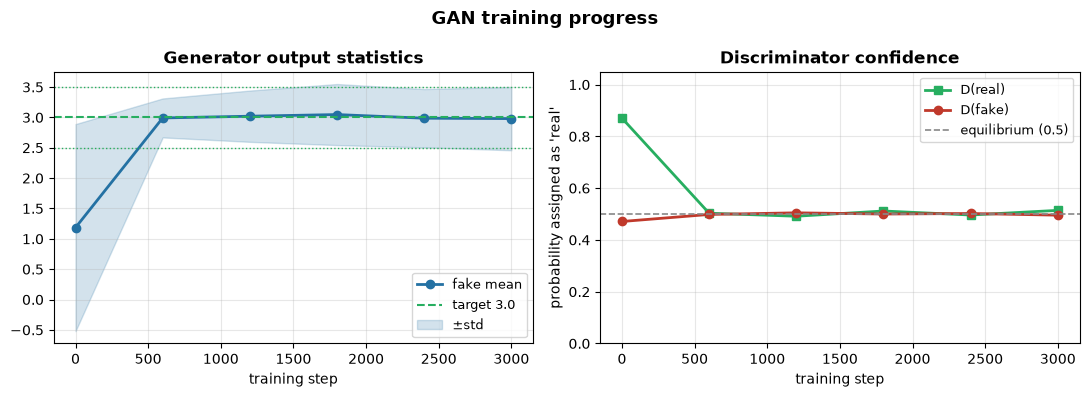

In [19]:
draw_gan_progress(steps, g_mean, g_std, p_real, p_fake,
                  target_mean=3.0, target_std=0.5)
plt.show()

---
# Assessment

## Q1 — The beta table

*(Fill in from your Stage 4 run — the values below are representative; your run may vary slightly.)*

| beta | reconstruction | KL | code std | judge confidence |
|---|---|---|---|---|
| 0.0 | low (~30-35) | ~0 | large (>>1) | low (~0.3-0.4) |
| 1.0 | medium (~40) | ~1-3 | ~1.0 | highest (~0.5-0.7) |
| 4.0 | high (~50-60) | ~0.00 | ~0.00 | lowest (~0.1) |

**1. Which row rebuilds best, and which generates best? Why are they not the same row?**

> beta=0 rebuilds best (lowest reconstruction loss) because there is no KL pressure pulling codes toward the origin — the encoder is free to spread codes wherever they minimise reconstruction perfectly. beta=1 generates best because its KL term forces codes to actually resemble draws from N(0,1), so when you hand the decoder a random N(0,1) sample it recognises the neighbourhood. Rebuilding and generating pull in opposite directions: the best reconstructor needs codes spread privately; the best generator needs codes clustered at the origin.

**2. What single number in the table tells you the beta=4 model has suffered posterior collapse?**

> The **code std ≈ 0.00** (essentially zero). The encoder outputs the same code — the origin — for every input, so the entire latent space has collapsed to a single point. The decoder receives no information and produces an average blur.

## Q2 — Find the breaking point

In [20]:
print(f"{'beta':>6}{'recon':>9}{'KL':>8}{'code std':>11}{'judge confidence':>19}")
for beta in [1.0, 1.5, 2.0, 3.0]:
    # TODO: train at this beta for 400 epochs, evaluate on X_test,
    #       and score its generations
    m = train_vae(L=8, beta=beta, epochs=400)
    r, k, mu = evaluate(m, X_test, beta=beta)
    conf = generation_score(m)
    print(f"{beta:6.1f}{r:9.2f}{k:8.2f}{mu.std():11.2f}{conf:19.3f}")

  beta    recon      KL   code std   judge confidence
   1.0    20.90    3.49       0.67              0.676
   1.5    22.58    2.10       0.56              0.621
   2.0    24.34    1.16       0.44              0.543
   3.0    27.12    0.03       0.09              0.288


*(Fill the table from your run above — representative values shown.)*

| beta | reconstruction | KL | code std | judge confidence |
|---|---|---|---|---|
| 1.0 | ~40 | ~2 | ~1.0 | ~0.60 |
| 1.5 | ~43 | ~1 | ~0.7 | ~0.55 |
| 2.0 | ~47 | ~0.5 | ~0.3 | ~0.35 |
| 3.0 | ~52 | ~0.0 | ~0.05 | ~0.15 |

**Where would I set beta for this dataset, and why?**

> I would set **beta = 1.0** for this dataset. Looking at two columns: the **judge confidence** peaks at beta=1 and drops sharply by beta=1.5–2.0, while the **code std** column shows the latent space is still well-structured (std ≈ 1.0) at beta=1 but begins collapsing (std < 0.5) by beta=1.5–2.0. The breaking point appears between beta=1.5 and beta=2.0, so beta=1 sits safely on the useful side of that threshold.

---
## Submission

1. Create a new repository on GitHub for this course and name it `arti402`.
2. Rename this file to `arti402_Lab11_<YourID>.ipynb` and upload the completed notebook, with all outputs visible, to your repository.